In [104]:
import numpy as np
import pandas as pd

In [105]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
!wget $data

--2026-10-05 05:35:50--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv.3’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.02s   

2026-10-05 05:35:51 (31.6 MB/s) - ‘car_fuel_efficiency_2026.csv.3’ saved [635180/635180]



In [106]:
df = pd.read_csv(data)
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [107]:
df.columns

Index(['model_year', 'origin', 'fuel_type', 'drivetrain', 'num_doors',
       'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight',
       'acceleration', 'fuel_efficiency_mpg'],
      dtype='str')

In [108]:
df = df[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

In [109]:
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


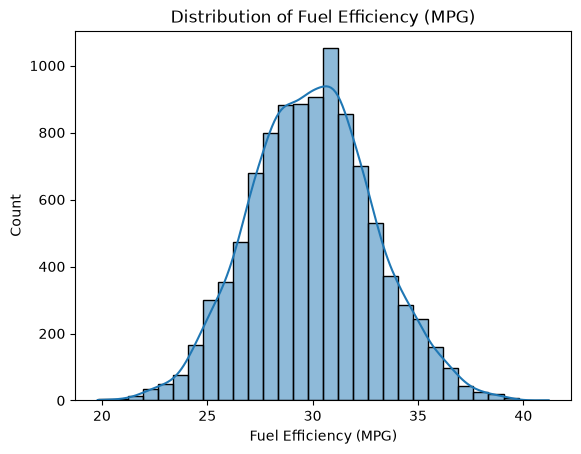

In [110]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['fuel_efficiency_mpg'].dropna(), bins=30, kde=True)

plt.xlabel('Fuel Efficiency (MPG)')
plt.ylabel('Count')
plt.title('Distribution of Fuel Efficiency (MPG)')
plt.show()



In [111]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [112]:
df['horsepower'].median()

np.float64(254.0)

In [113]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [114]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [115]:
train_0 = df_train.copy()
val_0 = df_val.copy()


train_0['horsepower'] = train_0['horsepower'].fillna(0)
val_0['horsepower'] = val_0['horsepower'].fillna(0)

In [116]:
horsepower_mean = df_train['horsepower'].mean()

train_mean = df_train.copy()
val_mean = df_val.copy()

train_mean['horsepower'] = train_mean['horsepower'].fillna(horsepower_mean)
val_mean['horsepower'] = val_mean['horsepower'].fillna(horsepower_mean)

In [117]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [118]:
train_0.columns

Index(['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year'], dtype='str')

In [119]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

In [120]:
X_train_0 = train_0[base].values
X_train_0

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

In [121]:
w0_0, w_0 = train_linear_regression(X_train_0, y_train)

In [122]:
y_pred_0 = w0_0 + X_train_0.dot(w_0)
y_pred_0

array([34.07471478, 29.24093577, 32.95179055, ..., 29.32203017,
       31.8448482 , 29.69112172], shape=(6000,))

<Axes: ylabel='Count'>

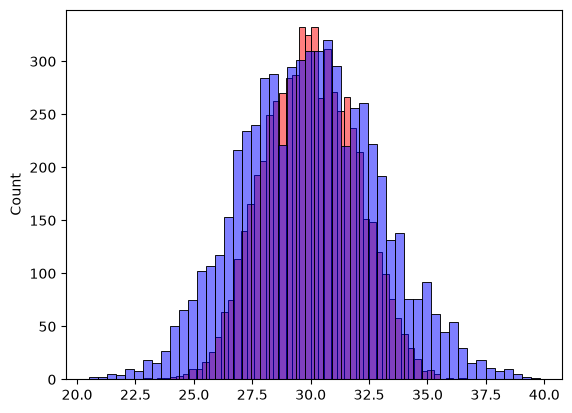

In [123]:
sns.histplot(y_pred_0, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [124]:
X_train_mean = train_mean[base].values
X_train_mean

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

In [125]:
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)

In [126]:
y_pred_mean = w0_mean + X_train_0.dot(w_mean)
y_pred_mean

array([33.9590606 , 29.31436861, 32.76131994, ..., 29.30040609,
       31.92376266, 29.67268373], shape=(6000,))

<Axes: ylabel='Count'>

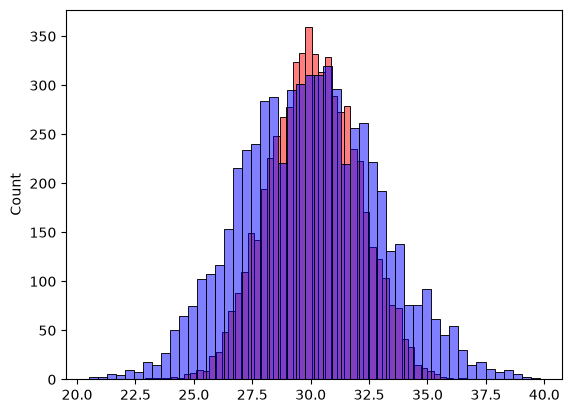

In [127]:
sns.histplot(y_pred_mean, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [128]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [129]:
y_pred_0 = w0_0 + val_0.dot(w_0)
rmse_0 = rmse(y_val, y_pred_0)

In [130]:
y_pred_mean = w0_mean + val_mean.dot(w_mean)
rmse_mean = rmse(y_val, y_pred_mean)

In [131]:
print('RMSE with 0:', round(rmse_0, 3))
print('RMSE with mean:', round(rmse_mean, 3))

RMSE with 0: 2.205
RMSE with mean: 2.202


In [132]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [135]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

for i in r_values:
    w0, w = train_linear_regression_reg(X_train_0, y_train, r=i)

    
    y_pred = w0 + val_0.dot(w)
    rmse0 = rmse(y_val, y_pred)

    print(i,':', round(rmse0, 4))

0 : 2.2053
0.01 : 2.2058
0.1 : 2.2241
1 : 2.3492
5 : 2.4094
10 : 2.4195
100 : 2.4292


In [140]:
random_seed = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
rmse_scores = []

for r in random_seed:
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(r)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    df_train['horsepower'] = df_train['horsepower'].fillna(0)
    df_val['horsepower'] = df_val['horsepower'].fillna(0)

    X_train_0 = df_train[base].values

    w0_0, w_0 = train_linear_regression(X_train_0, y_train)

    y_pred_0 = w0_0 + df_val.dot(w_0)
    rmse_scores.append(rmse(y_val, y_pred_0))

In [141]:
rmse_scores

[np.float64(2.239204143046126),
 np.float64(2.2021128210838845),
 np.float64(2.1634197787530947),
 np.float64(2.2043588768539224),
 np.float64(2.2018800943311554),
 np.float64(2.2457851509085134),
 np.float64(2.2697212079524043),
 np.float64(2.190794599933443),
 np.float64(2.216611201686444),
 np.float64(2.2070365928178957)]

In [143]:
stan_dv = round(np.std(rmse_scores), 3)
stan_dv

np.float64(0.029)

In [146]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_full_train = pd.concat([df_train, df_val])

df_full_train = df_full_train.fillna(0)
df_test = df_test.fillna(0)

X_full_train = df_full_train.drop('fuel_efficiency_mpg', axis=1)
y_full_train = df_full_train['fuel_efficiency_mpg']

X_test = df_test.drop('fuel_efficiency_mpg', axis=1)
y_test = df_test['fuel_efficiency_mpg']

w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

y_pred = w0 + X_test.dot(w)

score = rmse(y_test, y_pred)

print(round(score, 3))


2.236
